# 02 — Causal features and leakage-safe preprocessing

**Question:** can bounded, observable request history predict reuse within a fixed horizon? Analysis executes on this MacBook; inputs are the real Raspberry Pi collection from Notebook 01. No test data are generated or opened. A prediction is made after the current request, so that request is included in historical counts. Public key IDs identify context within a session but are excluded from predictors.

All times below use the externally generated scheduled-arrival clock. Labels are next-arrival events, not measured service duration. Maximum history is 50 ms and candidate horizons are 5, 10 and 20 ms. Every row used for model comparison has the full 50 ms history and full 20 ms follow-up; right-censored rows are excluded rather than labelled as non-reuse.

All history-inclusion tests use integer nanoseconds. An earlier cross-language parity check exposed a one-request difference at the 50 ms boundary in bursty traffic; the integer representation removes it, and no policy evaluation used the earlier version.

In [1]:
from pathlib import Path
import hashlib, json, re, platform
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown, HTML
# Resolve the repository root from either the root directory or notebooks/.
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "notebooks").is_dir() and (p / "dataset").is_dir()), None)
assert ROOT is not None, "run this notebook from inside the repository"
def relocate(rel):
    """Map a path recorded at acquisition time (original project layout) onto this repository's layout."""
    rel = str(rel)
    for old, new in (("Dataset/Raw/PiExperiments/", "dataset/raw/"), ("Dataset/Raw/", "dataset/raw/"), ("Raw/", "raw/"),
                     ("Dataset/Interim/", "dataset/interim/"), ("Dataset/Processed/", "dataset/processed/"),
                     ("Dataset/Splits/", "dataset/splits/"), ("Dataset/Provenance/", "dataset/provenance/"),
                     ("Artifacts/Models/", "support/models/"), ("Artifacts/Binaries/", "support/binaries/"),
                     ("Configs/", "support/configs/"), ("Manifests/", "support/manifests/"), ("Native/", "support/native/"),
                     ("Reports/CoreCalibration/", "support/calibration/"), ("Tables/", "artifacts/"), ("Figures/", "figures/")):
        if rel.startswith(old):
            return new + rel[len(old):]
    return rel
def acquisition_path(path):
    """Inverse of relocate: a repository path written in the acquisition-time layout used inside frozen records."""
    path = Path(path)
    rel = str(path.resolve().relative_to(ROOT)) if path.is_absolute() else str(path)
    for old, new in (("dataset/raw/MLKEM_TestVectors/", "Dataset/Raw/MLKEM_TestVectors/"), ("dataset/raw/IoT23/", "Dataset/Raw/IoT23/"),
                     ("dataset/raw/", "Dataset/Raw/PiExperiments/"), ("dataset/interim/", "Dataset/Interim/"),
                     ("dataset/processed/", "Dataset/Processed/"), ("dataset/splits/", "Dataset/Splits/"),
                     ("dataset/provenance/", "Dataset/Provenance/"), ("support/models/", "Artifacts/Models/"),
                     ("support/binaries/", "Artifacts/Binaries/"), ("support/configs/", "Configs/"), ("support/manifests/", "Manifests/"),
                     ("support/native/", "Native/"), ("support/calibration/", "Reports/CoreCalibration/"),
                     ("artifacts/", "Tables/"), ("figures/", "Figures/")):
        if rel.startswith(old):
            return new + rel[len(old):]
    return rel
DATA = ROOT / "dataset"
RAW = DATA / "raw"
TABLES, FIGURES = ROOT / "artifacts", ROOT / "figures"
for p in (TABLES, FIGURES, DATA / "interim", DATA / "splits"):
    p.mkdir(exist_ok=True)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 180)
try:
    font_manager.findfont("Times New Roman", fallback_to_default=False); FONT_FAMILY = "Times New Roman"
except ValueError:
    FONT_FAMILY = "serif"  # the published figures use Times New Roman; any serif font keeps the layout
mpl.rcParams.update({"font.family": FONT_FAMILY, "font.size":18,
    "axes.titlesize":20,"axes.labelsize":20,"xtick.labelsize":18,
    "ytick.labelsize":18,"legend.fontsize":18,"figure.dpi":350,
    "savefig.dpi":350,"axes.unicode_minus":True,"pdf.fonttype":42})
COLORS = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#4D4D4D"]

def save_table(frame, name, *, show=True, exclude=(), columns=None):
    frame.to_csv(TABLES / f"02_{name}.csv", index=True)
    frame.to_latex(TABLES / f"02_{name}.tex", index=True, float_format="%.3f")
    if show:
        visible = frame.loc[:, columns] if columns is not None else frame.drop(columns=list(exclude))
        display(visible)
def save_figure(fig, name, source):
    # Compact physical canvas, unchanged 18/20 pt text. Wrap instead of shrinking.
    import textwrap
    for axis in fig.axes:
        if axis.get_title():
            axis.set_title(textwrap.fill(axis.get_title().replace("\n", " "), width=max(32, int(fig.get_figwidth()*5))))
        label=axis.get_xlabel()
        if label and len(label)>44:
            axis.set_xlabel(textwrap.fill(label.replace("\n", " "),width=44))
    fig.set_layout_engine("constrained")
    fig.savefig(FIGURES / f"02_{name}.png", dpi=350, bbox_inches="tight")
    fig.savefig(FIGURES / f"02_{name}.pdf", dpi=350, bbox_inches="tight")
    source.to_csv(TABLES / f"02_{name}_source.csv", index=False)
    plt.show()
    plt.close(fig)

from collections import deque
from sklearn.feature_selection import mutual_info_classif
from scipy.stats import spearmanr


## 02.1 — Verify upstream artifacts and session boundaries

In [2]:
upstream = json.loads((ROOT/"support/manifests/NotebookRuns/01_derived_hashes.json").read_text())
for name, expected in upstream.items():
    assert hashlib.sha256((ROOT/relocate(name)).read_bytes()).hexdigest() == expected, name
events = pd.read_parquet(DATA/"interim/development_events.parquet")
sessions = pd.read_csv(DATA/"splits/development_session_assignments.csv")
assert set(events.split)=={"train","development"}
assert not events.duplicated(["session_id","request_id"]).any()
train_ids=set(sessions.loc[sessions.split.eq("train"),"session_id"])
dev_ids=set(sessions.loc[sessions.split.eq("development"),"session_id"])
assert train_ids.isdisjoint(dev_ids)
save_table(sessions.groupby(["split","workload_id"]).agg(sessions=("session_id","size"),requests=("requests","sum")),"input_coverage", show=False)


## 02.2 — Observable features and future-only labels

Counts include the current request. `gap50` is the previous same-context interval, clipped at 50 ms; a new/unseen context has value 50. `gap_cv` uses only same-context intervals wholly inside the 50 ms window (zero with fewer than two intervals). `exp10` is a sum of exponentially decaying historical hits with 10 ms time constant, **truncated at 50 ms**, not an unbounded running state. `share_shift` compares the current 5 ms context share with its preceding 45 ms share. Global rates count all requests, including the current one. No measured latency, cache hit, workload family, context identity or future label is an input. Queue depth is absent and will not be invented.

In [3]:
FEATURES=["c5","c10","c20","c50","gap50","gap_mean","gap_cv","exp10","share_shift","rate5","rate50"]
HORIZONS=[5,10,20]
HISTORY_MS=50.0
PURGE_MS=70.0

def causal_features(times_ms, keys):
    # Integer timestamp boundaries avoid cross-language floating-point window drift.
    times_ns=np.rint(np.asarray(times_ms)*1e6).astype(np.int64)
    history=deque()
    rows=[]
    for t, key in zip(times_ns, keys):
        while history and history[0][0] < t-50_000_000:
            history.popleft()
        history.append((int(t),int(key)))
        same=np.array([v for v,k in history if k==key],dtype=np.int64)
        ages_ns=t-same
        counts=[int(np.count_nonzero(ages_ns<=h*1_000_000)) for h in [5,10,20,50]]
        gaps=np.diff(same)/1e6
        gap50=min(50.0,float(gaps[-1])) if len(gaps) else 50.0
        mean=float(gaps.mean()) if len(gaps) else 50.0
        cv=float(gaps.std()/mean) if len(gaps)>=2 and mean>0 else 0.0
        g5=sum(t-v<=5_000_000 for v,k in history)
        g50=len(history)
        shift=abs(counts[0]/g5-(counts[3]-counts[0])/max(1,g50-g5))
        rows.append(counts+[gap50,mean,cv,float(np.exp(-ages_ns/10_000_000).sum()),shift,g5/5,g50/50])
    return np.asarray(rows,dtype=float)

def future_reuse_labels(times_ns, keys, horizons_ms):
    # Reuse in (t, t+h], with a fully observed horizon required for every label.
    times_ns=np.asarray(times_ns,dtype=np.int64)
    keys=np.asarray(keys)
    assert times_ns.ndim==1 and len(times_ns)==len(keys) and len(times_ns)>0
    assert np.all(np.diff(times_ns)>0)
    next_gap=np.full(len(times_ns),np.iinfo(np.int64).max,dtype=np.int64)
    future={}
    for i in range(len(times_ns)-1,-1,-1):
        key=int(keys[i])
        if key in future:
            next_gap[i]=future[key]-times_ns[i]
        future[key]=times_ns[i]
    return {h:np.where(times_ns<=times_ns[-1]-h*1_000_000,
                       (next_gap<=h*1_000_000).astype(float),np.nan)
            for h in horizons_ms}

frames=[]
for sid,g in events.groupby("session_id",sort=True):
    g=g.sort_values("request_id").reset_index(drop=True)
    times_ns=g.scheduled_arrival_ns.to_numpy()-g.scheduled_arrival_ns.iloc[0]
    times=times_ns/1e6
    keys=g.key_id.to_numpy()
    assert np.all(np.diff(times)>0)
    x=causal_features(times,keys)
    labels=future_reuse_labels(times_ns,keys,HORIZONS)
    f=g[["session_id","request_id","workload_id","split","key_id"]].copy()
    f["row_id"]=f.session_id+":"+f.request_id.astype(str)
    f["schedule_ms"]=times
    f["schedule_ns"]=times_ns
    f["eligible"]=(times_ns>=50_000_000)&(times_ns<=times_ns[-1]-max(HORIZONS)*1_000_000)
    for h in HORIZONS:
        f[f"y{h}"]=labels[h]
    f[FEATURES]=x
    frames.append(f)
features=pd.concat(frames,ignore_index=True)
model_data=features.loc[features.eligible].copy()
assert np.isfinite(model_data[FEATURES].to_numpy()).all()
assert model_data[[f"y{h}" for h in HORIZONS]].notna().all().all()
save_table(features.groupby("split").agg(all_rows=("row_id","size"),eligible_rows=("eligible","sum")),"eligibility", show=False)
save_table(pd.DataFrame({"feature":FEATURES,"unit":["requests"]*4+["ms","ms","ratio","weighted requests","share difference","requests/ms","requests/ms"],"maximum_history_ms":50}).set_index("feature"),"feature_dictionary")


,unit,maximum_history_ms
feature,,
c5,requests,50
c10,requests,50
c20,requests,50
c50,requests,50
gap50,ms,50
gap_mean,ms,50
gap_cv,ratio,50
exp10,weighted requests,50
share_shift,share difference,50


## 02.3 — Adversarial causality and boundary checks

Change the suffix and future key identities, then verify that every prefix feature is bit-identical. The production label function is also tested against hand-specified miniature schedules: next reuse one nanosecond before, exactly at, and one nanosecond after each horizon; a different context inside the horizon; and the exact observation-end boundary. A label is defined on (t, t+h], and the complete horizon must be observed. Even an observed early reuse is excluded if its horizon extends beyond the observation end, consistently with the complete-window analysis population. These deterministic fixtures are implementation checks, not experimental samples and never enter fitting, validation or test sets.


In [4]:
g=events.loc[events.session_id.eq(sorted(train_ids)[0])].sort_values("request_id")
t=(g.scheduled_arrival_ns.to_numpy()-g.scheduled_arrival_ns.iloc[0])/1e6
k=g.key_id.to_numpy().copy()
prefix=613
original=causal_features(t,k)
perturbed=k.copy(); perturbed[prefix:]=(perturbed[prefix:]+17)%64
assert np.array_equal(original[:prefix],causal_features(t,perturbed)[:prefix])
assert np.array_equal(original[:prefix],causal_features(t[:prefix],k[:prefix]))
# An old request exactly outside the bounded window cannot affect the current feature.
a=causal_features(np.array([0.,1.,51.01]),np.array([1,2,2]))[-1]
b=causal_features(np.array([0.,1.,51.01]),np.array([999,2,2]))[-1]
assert np.array_equal(a,b)
# Direct next-arrival checks independent of feature construction.
for sid,g in features.groupby("session_id"):
    for key,q in g.groupby("key_id"):
        gap=q.schedule_ns.shift(-1)-q.schedule_ns
        valid=q.eligible
        for h in HORIZONS:
            assert np.array_equal(q.loc[valid,f"y{h}"].to_numpy(),gap.loc[valid].le(h*1_000_000).astype(float).to_numpy())
# Miniature fixtures exercise the SAME function used for the real labels above.
# Expectations are literal, independently specified values, not generated labels.
label_fixture_rows=[]
manual_gaps=[
    (4_999_999,1.,1.,1.),(5_000_000,1.,1.,1.),(5_000_001,0.,1.,1.),
    (9_999_999,0.,1.,1.),(10_000_000,0.,1.,1.),(10_000_001,0.,0.,1.),
    (19_999_999,0.,0.,1.),(20_000_000,0.,0.,1.),(20_000_001,0.,0.,0.)]
for gap_ns,*expected_values in manual_gaps:
    got=future_reuse_labels([0,gap_ns,40_000_000],[7,7,99],HORIZONS)
    for h,expected in zip(HORIZONS,expected_values):
        actual=float(got[h][0])
        assert actual==expected,("reuse boundary",gap_ns,h,actual,expected)
        label_fixture_rows.append({"Case":"Reuse boundary","Horizon_ms":h,"Next_same_context_ns":gap_ns,
                                   "Observation_end_ns":40_000_000,"Expected":expected,"Actual":actual})
# A different context at 5 ms must not count as reuse of context 7.
got=future_reuse_labels([0,5_000_000,20_000_000,40_000_000],[7,99,7,99],HORIZONS)
for h,expected in zip(HORIZONS,[0.,0.,1.]):
    actual=float(got[h][0]);assert actual==expected
    label_fixture_rows.append({"Case":"Other context ignored","Horizon_ms":h,"Next_same_context_ns":20_000_000,
                               "Observation_end_ns":40_000_000,"Expected":expected,"Actual":actual})
for h in HORIZONS:
    horizon_ns=h*1_000_000
    # A completely observed horizon with no reuse has a negative label.
    actual=float(future_reuse_labels([0,horizon_ns],[7,99],[h])[h][0])
    assert actual==0.
    label_fixture_rows.append({"Case":"Complete horizon; no reuse","Horizon_ms":h,"Next_same_context_ns":np.nan,
                               "Observation_end_ns":horizon_ns,"Expected":0.,"Actual":actual})
    # A horizon shorter by 1 ns is censored, even if reuse has already occurred.
    for terminal_key,case in [(99,"Censored; no observed reuse"),(7,"Censored; observed reuse")]:
        got=future_reuse_labels([0,horizon_ns-1],[7,terminal_key],[h])[h]
        assert np.isnan(got).all()
        label_fixture_rows.append({"Case":case,"Horizon_ms":h,
                                   "Next_same_context_ns":horizon_ns-1 if terminal_key==7 else np.nan,
                                   "Observation_end_ns":horizon_ns-1,"Expected":np.nan,"Actual":float(got[0])})
# The 50 ms historical window includes its left boundary but excludes 1 ns earlier.
assert causal_features(np.array([0.,50.]),np.array([7,7]))[-1,FEATURES.index("c50")]==2.
assert causal_features(np.array([0.,50.000001]),np.array([7,7]))[-1,FEATURES.index("c50")]==1.
label_fixtures=pd.DataFrame(label_fixture_rows)
save_table(label_fixtures,"label_boundary_fixtures",show=False)
checks=pd.DataFrame({"check":["Prefix invariance after suffix mutation","Prefix invariance after truncation","Bounded history invariance","Independent next-arrival labels","No non-finite predictors","Disjoint outer sessions","Hand-specified horizon and censoring fixtures","Exact historical-window boundary"],"passed":[True]*8})
save_table(checks,"causality_checks")


,check,passed
0,Prefix invariance after suffix mutation,True
1,Prefix invariance after truncation,True
2,Bounded history invariance,True
3,Independent next-arrival labels,True
4,No non-finite predictors,True
5,Disjoint outer sessions,True
6,Hand-specified horizon and censoring fixtures,True
7,Exact historical-window boundary,True


## 02.4 — Target balance and history association
Descriptive associations use training sessions only. No association estimate is used to select features from development or test data. Workload-specific differences are evaluated rather than assuming one common class prevalence.

,rows,reuse_5ms,reuse_10ms,reuse_20ms
workload_id,,,,
abrupt,5160,0.638178,0.828876,0.900194
bursty,4836,0.856907,0.917701,0.965467
hotcold,5160,0.637403,0.833527,0.909690
nonstationary,5160,0.482171,0.591667,0.703101
periodic,5160,0.836434,0.836434,0.845349
poisson,5097,0.142437,0.266627,0.466941
thrashing,5160,0.000000,1.000000,1.000000
uniform,5160,0.153295,0.275388,0.464922
varying_contexts,5160,0.232946,0.350581,0.502132


,spearman_y10
feature,
c5,0.392797
c10,0.540424
c20,0.580106
c50,0.604615
gap50,-0.499321
gap_mean,-0.553689
gap_cv,0.318207
exp10,0.568475
share_shift,-0.092288


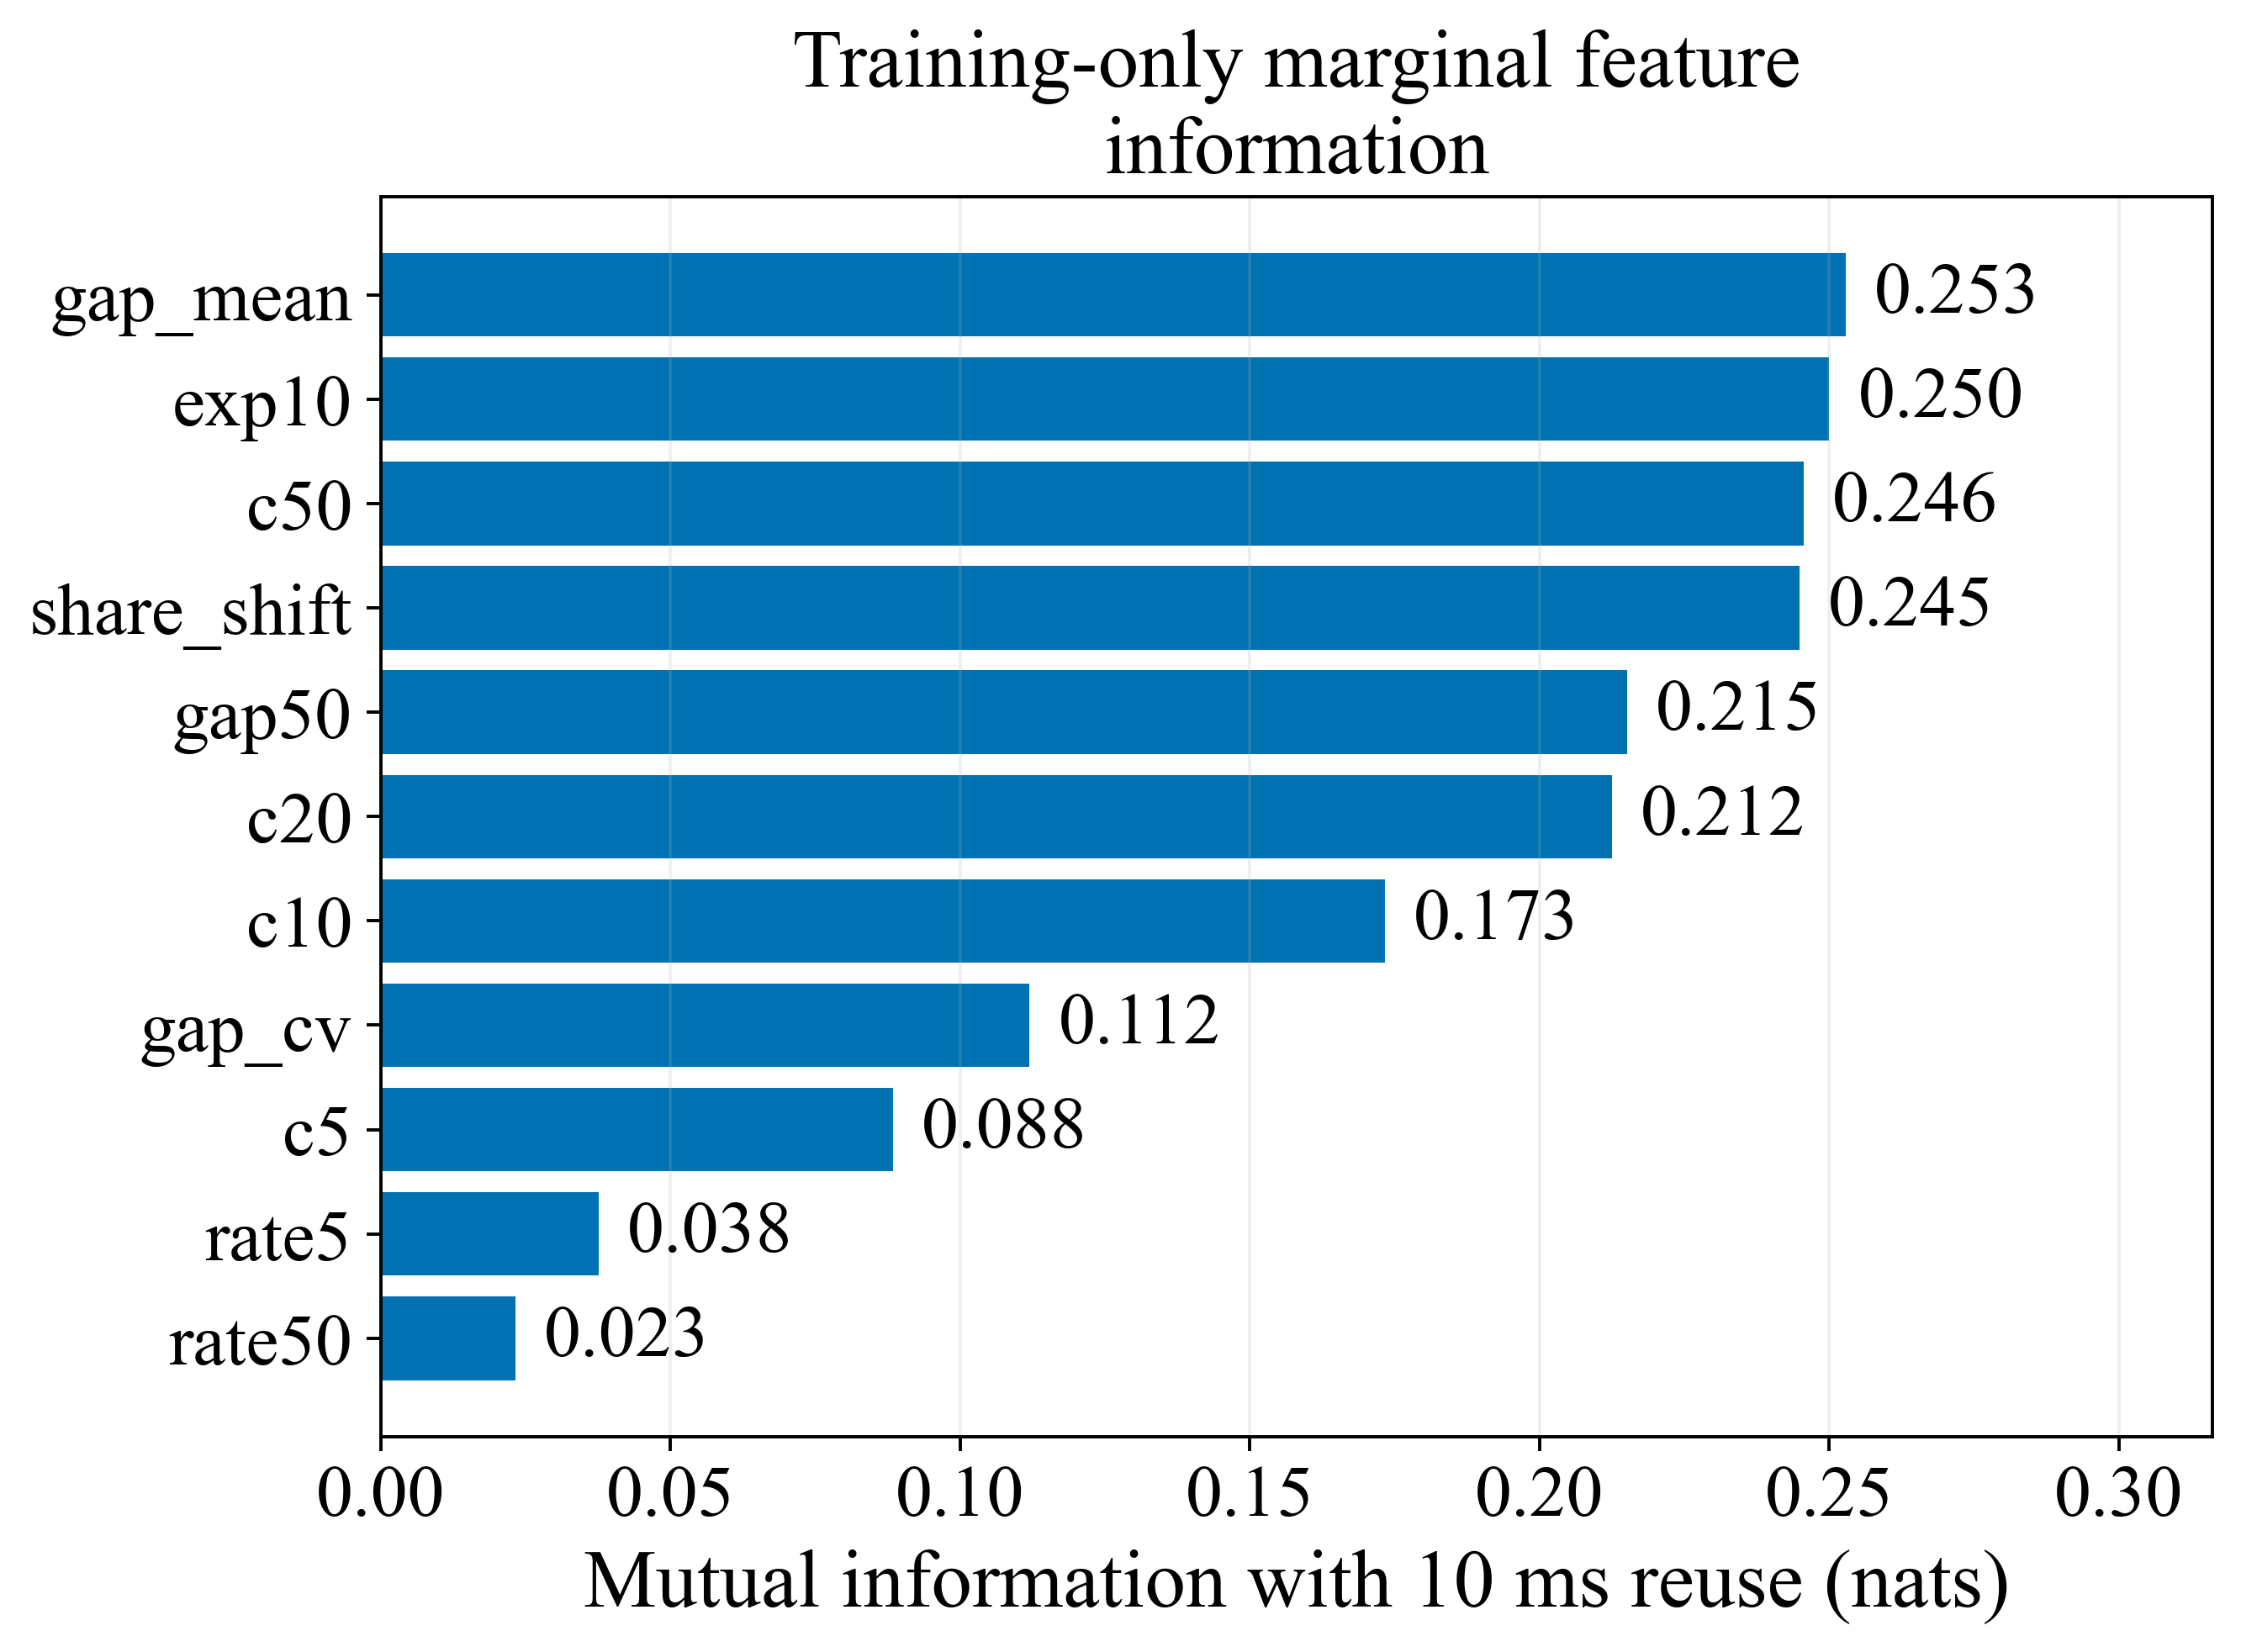

In [5]:
train=model_data.loc[model_data.split.eq("train")].copy()
dev=model_data.loc[model_data.split.eq("development")].copy()
balance=train.groupby("workload_id").agg(rows=("row_id","size"),reuse_5ms=("y5","mean"),reuse_10ms=("y10","mean"),reuse_20ms=("y20","mean"))
save_table(balance,"target_balance")
mi=mutual_info_classif(train[FEATURES],train.y10.astype(int),discrete_features=[True]*4+[False]*7,random_state=17)
association=pd.DataFrame({"feature":FEATURES,"spearman_y10":[spearmanr(train[f],train.y10).statistic for f in FEATURES],"mutual_information_nats":mi}).set_index("feature")
save_table(association,"training_associations", exclude=['mutual_information_nats'])
fig,ax=plt.subplots(figsize=(7.5,5.5))
ordered=association.sort_values("mutual_information_nats")
bars=ax.barh(ordered.index,ordered.mutual_information_nats,color=COLORS[0])
ax.bar_label(bars,fmt="%.3f",padding=7,fontsize=18)
ax.set_xlim(0,ordered.mutual_information_nats.max()*1.25)
ax.set(xlabel="Mutual information with 10 ms reuse (nats)",title="Training-only marginal feature information")
ax.grid(axis="x",alpha=.2)
save_figure(fig,"marginal_information",ordered.reset_index())


## 02.5 — Collinearity and stability across regimes
Spearman correlation describes rank redundancy. Workload-wise point-biserial/rank associations can change sign. The full small feature set is retained for controlled comparison; no PCA or clustering is added because the decision variables have direct time/count interpretations. Continuous inputs will be standardized inside each training fold for logistic regression. Trees receive unscaled values.

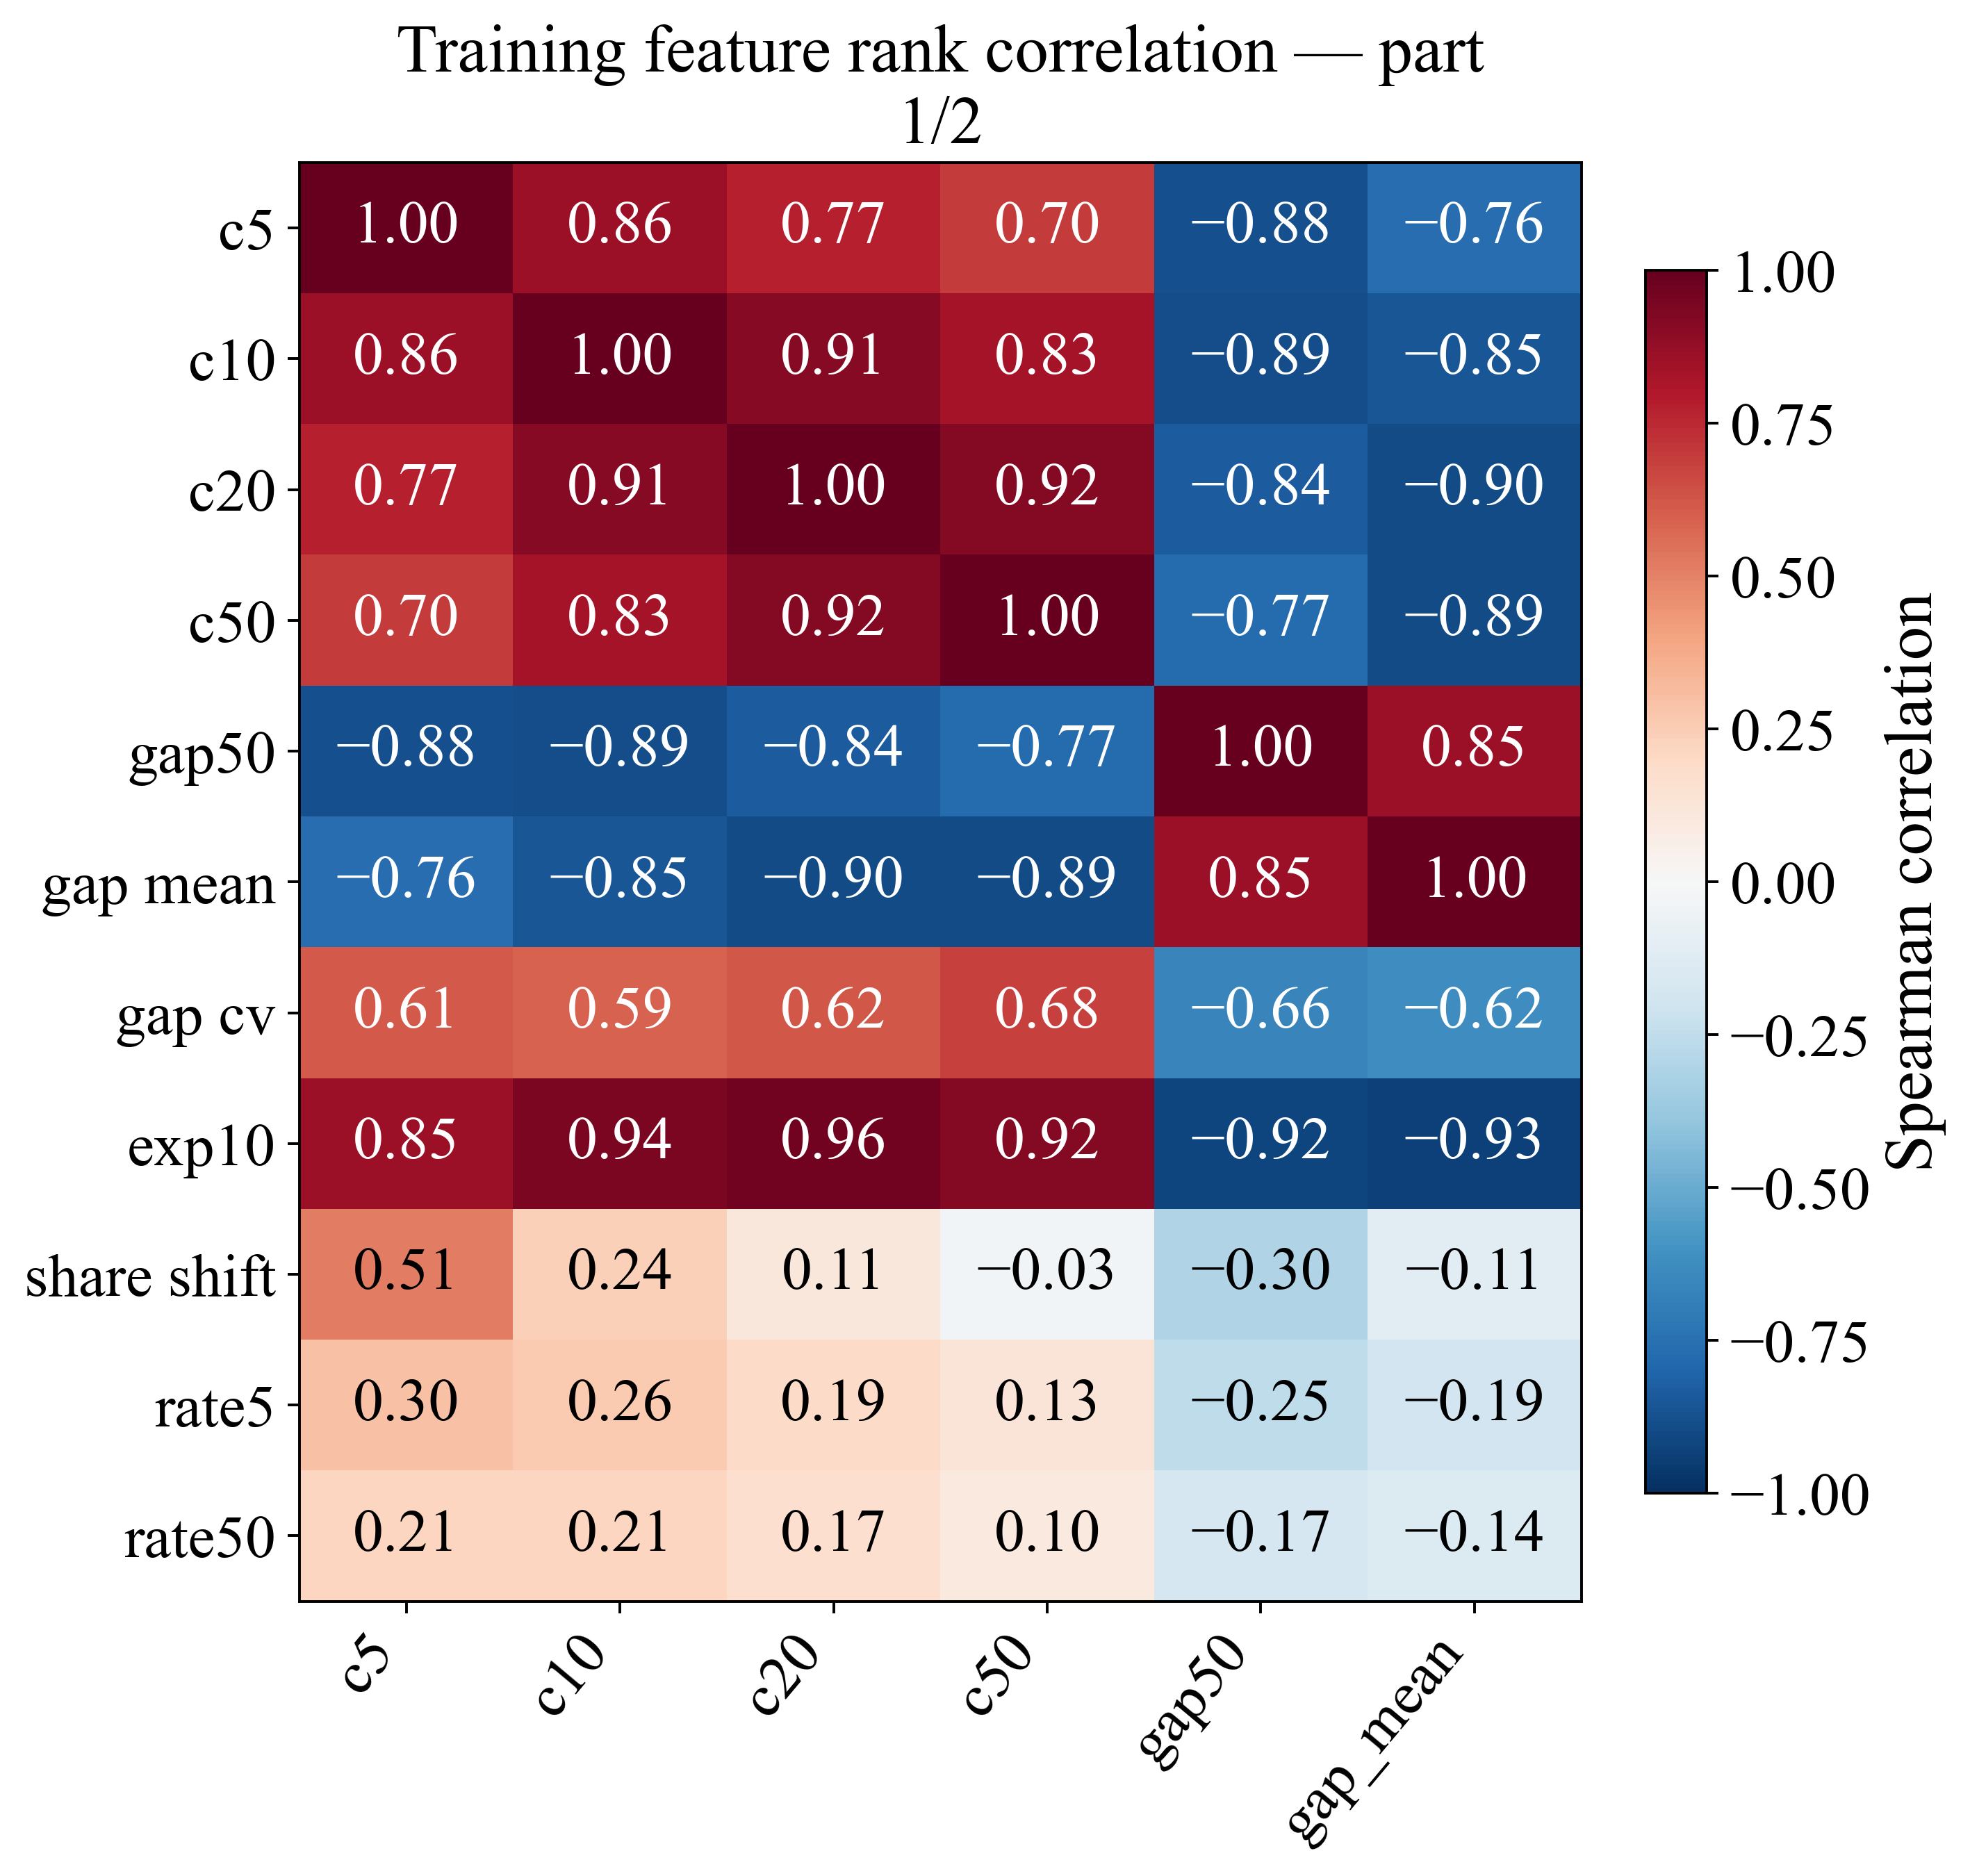

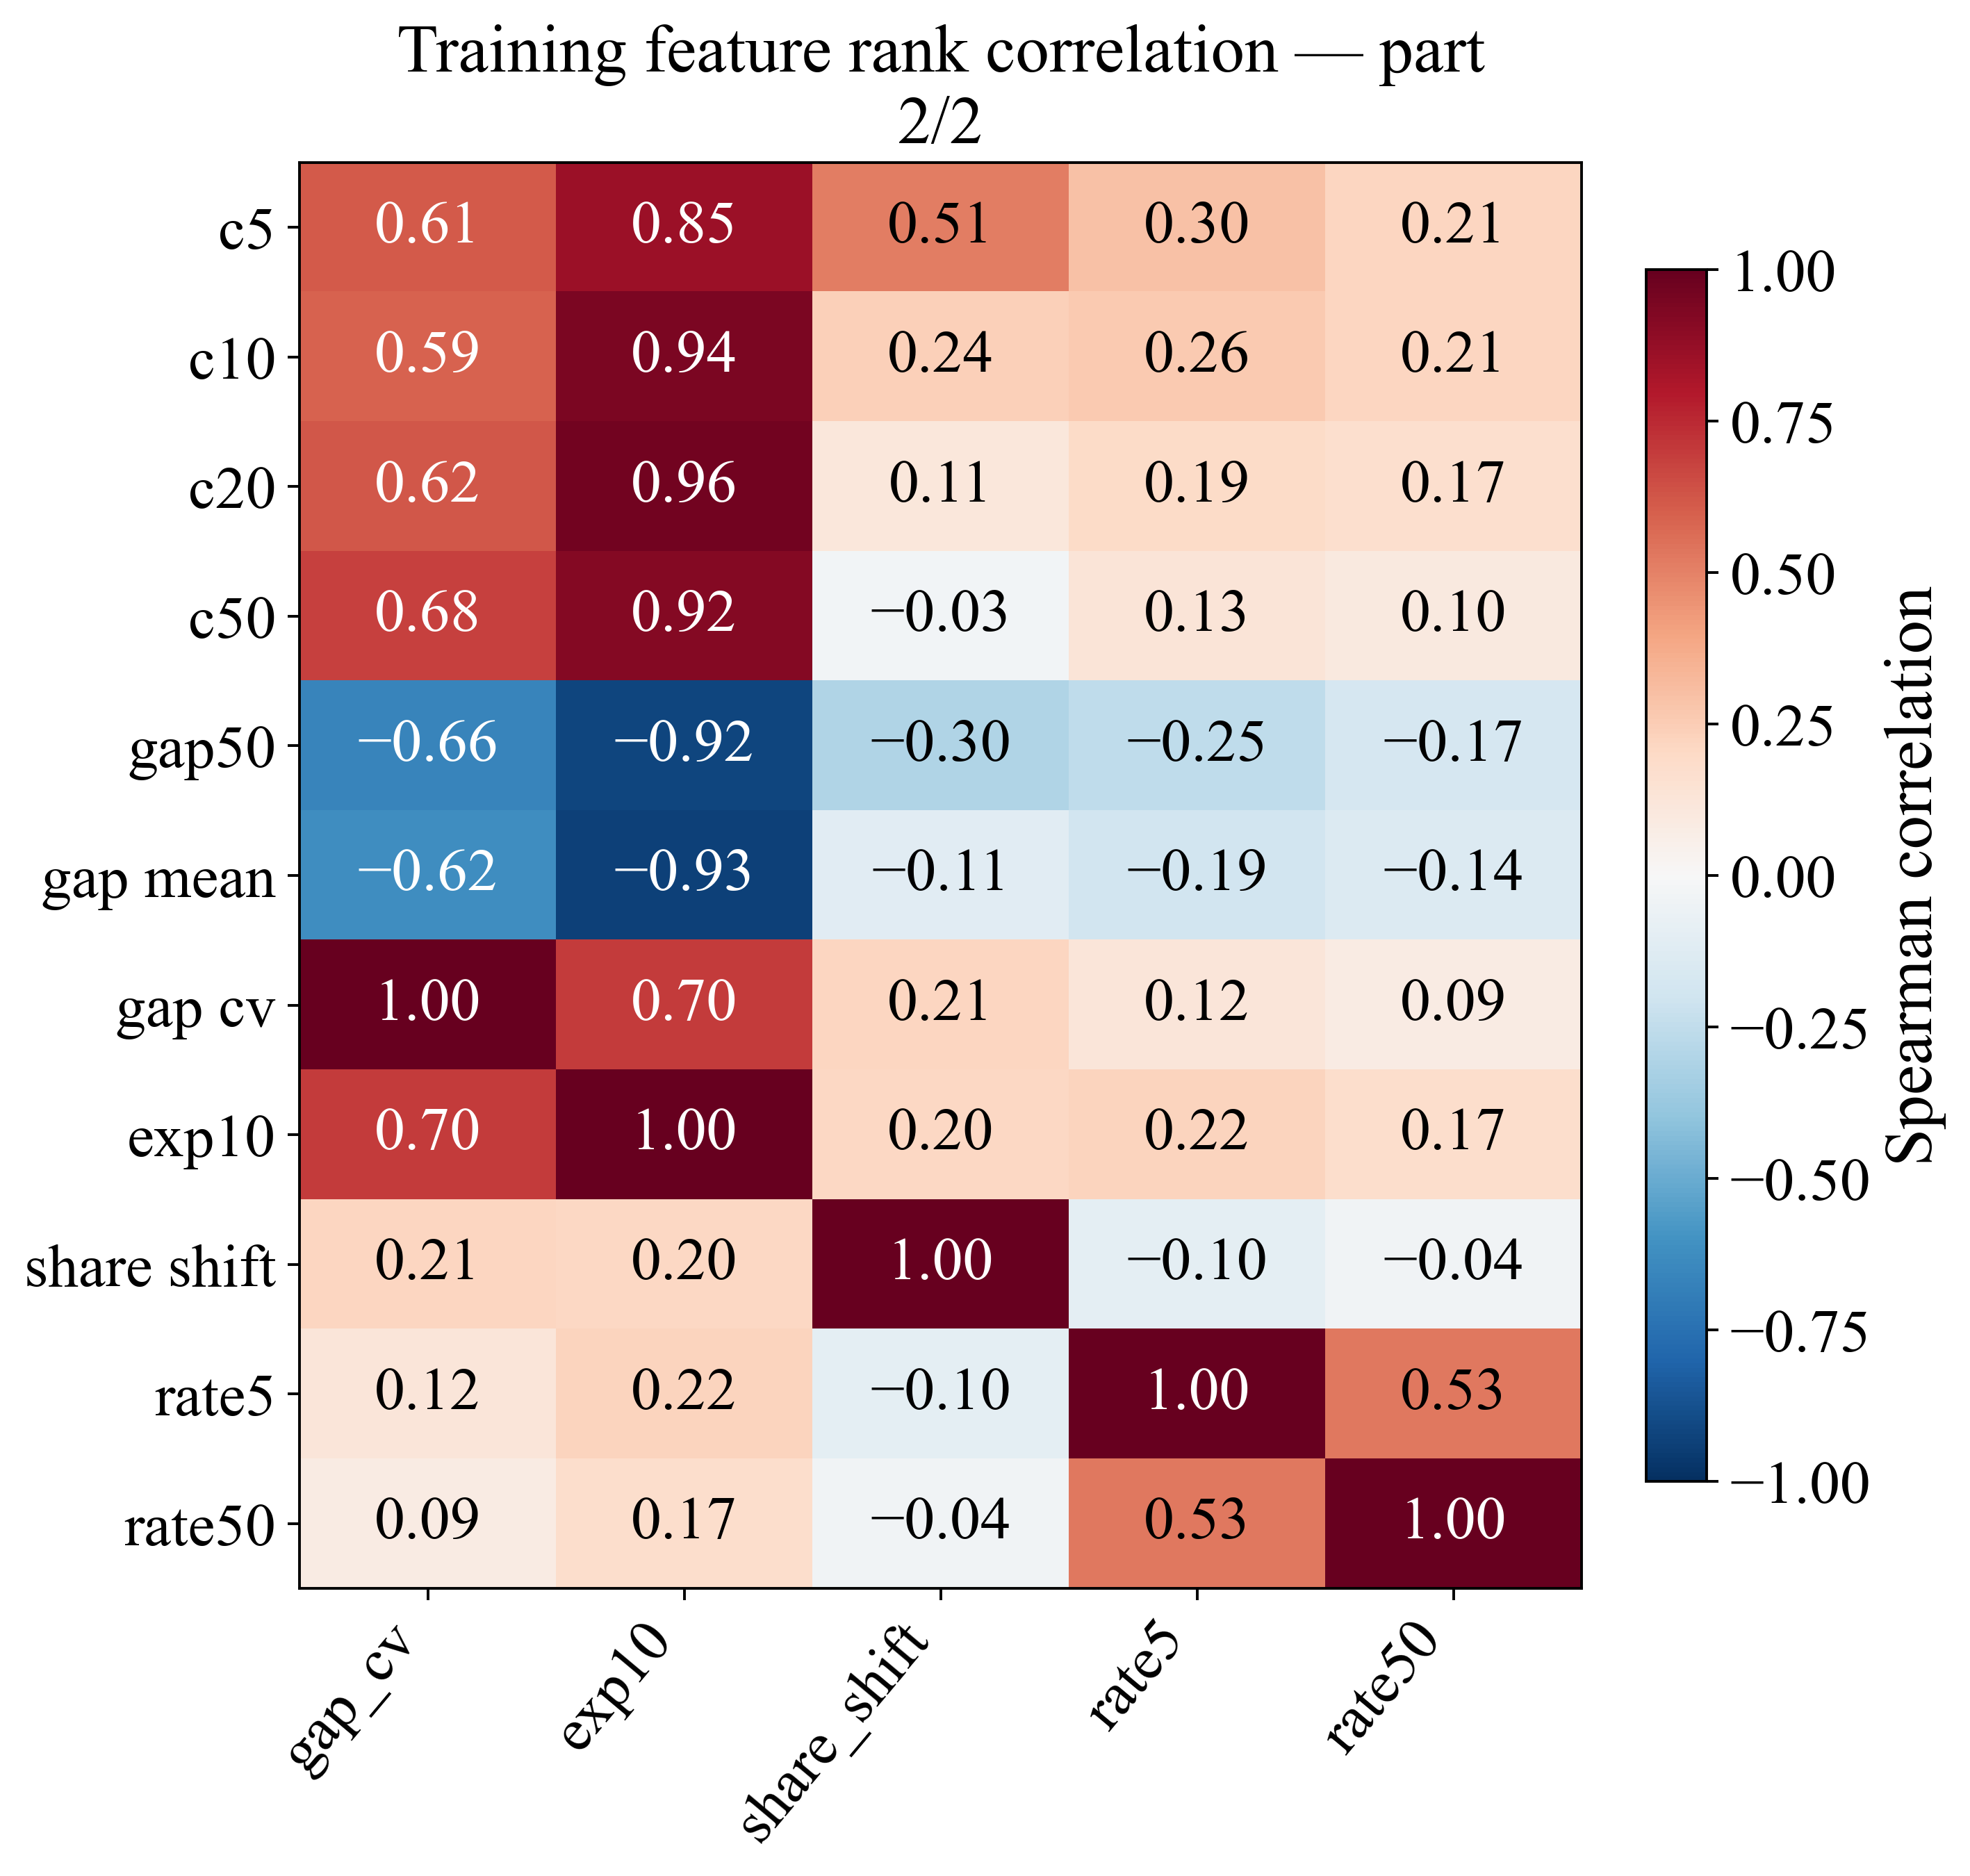

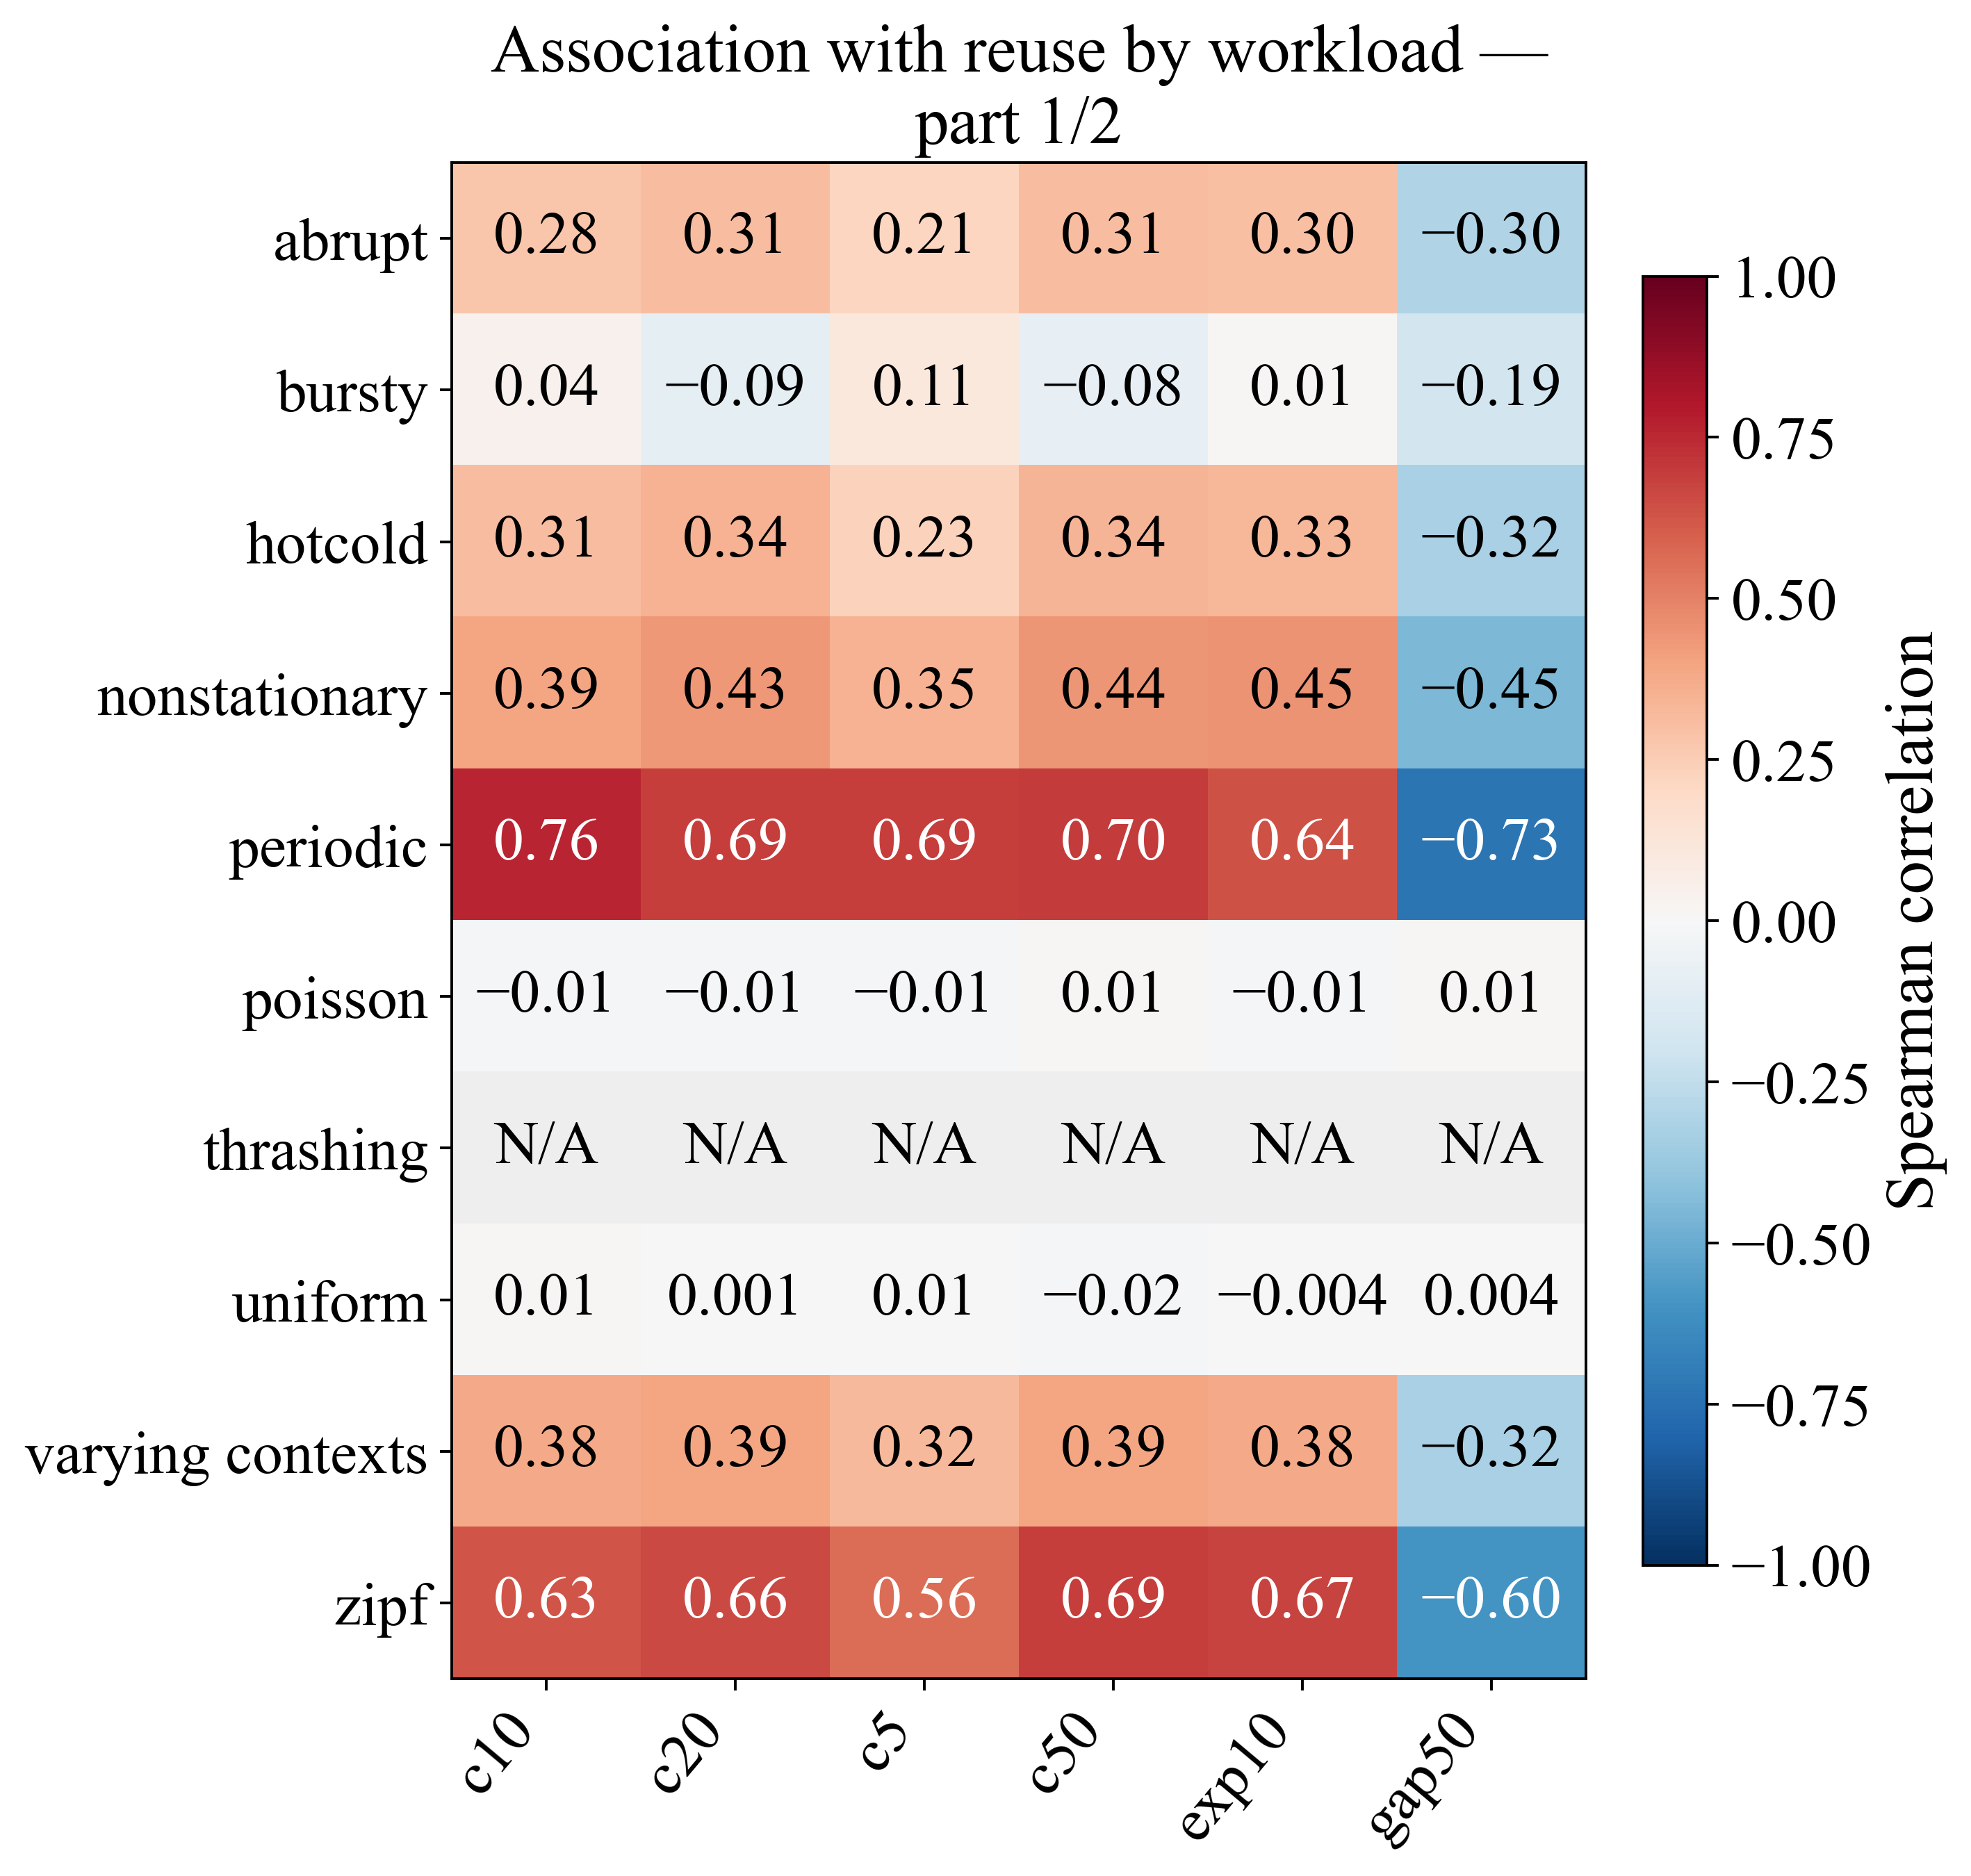

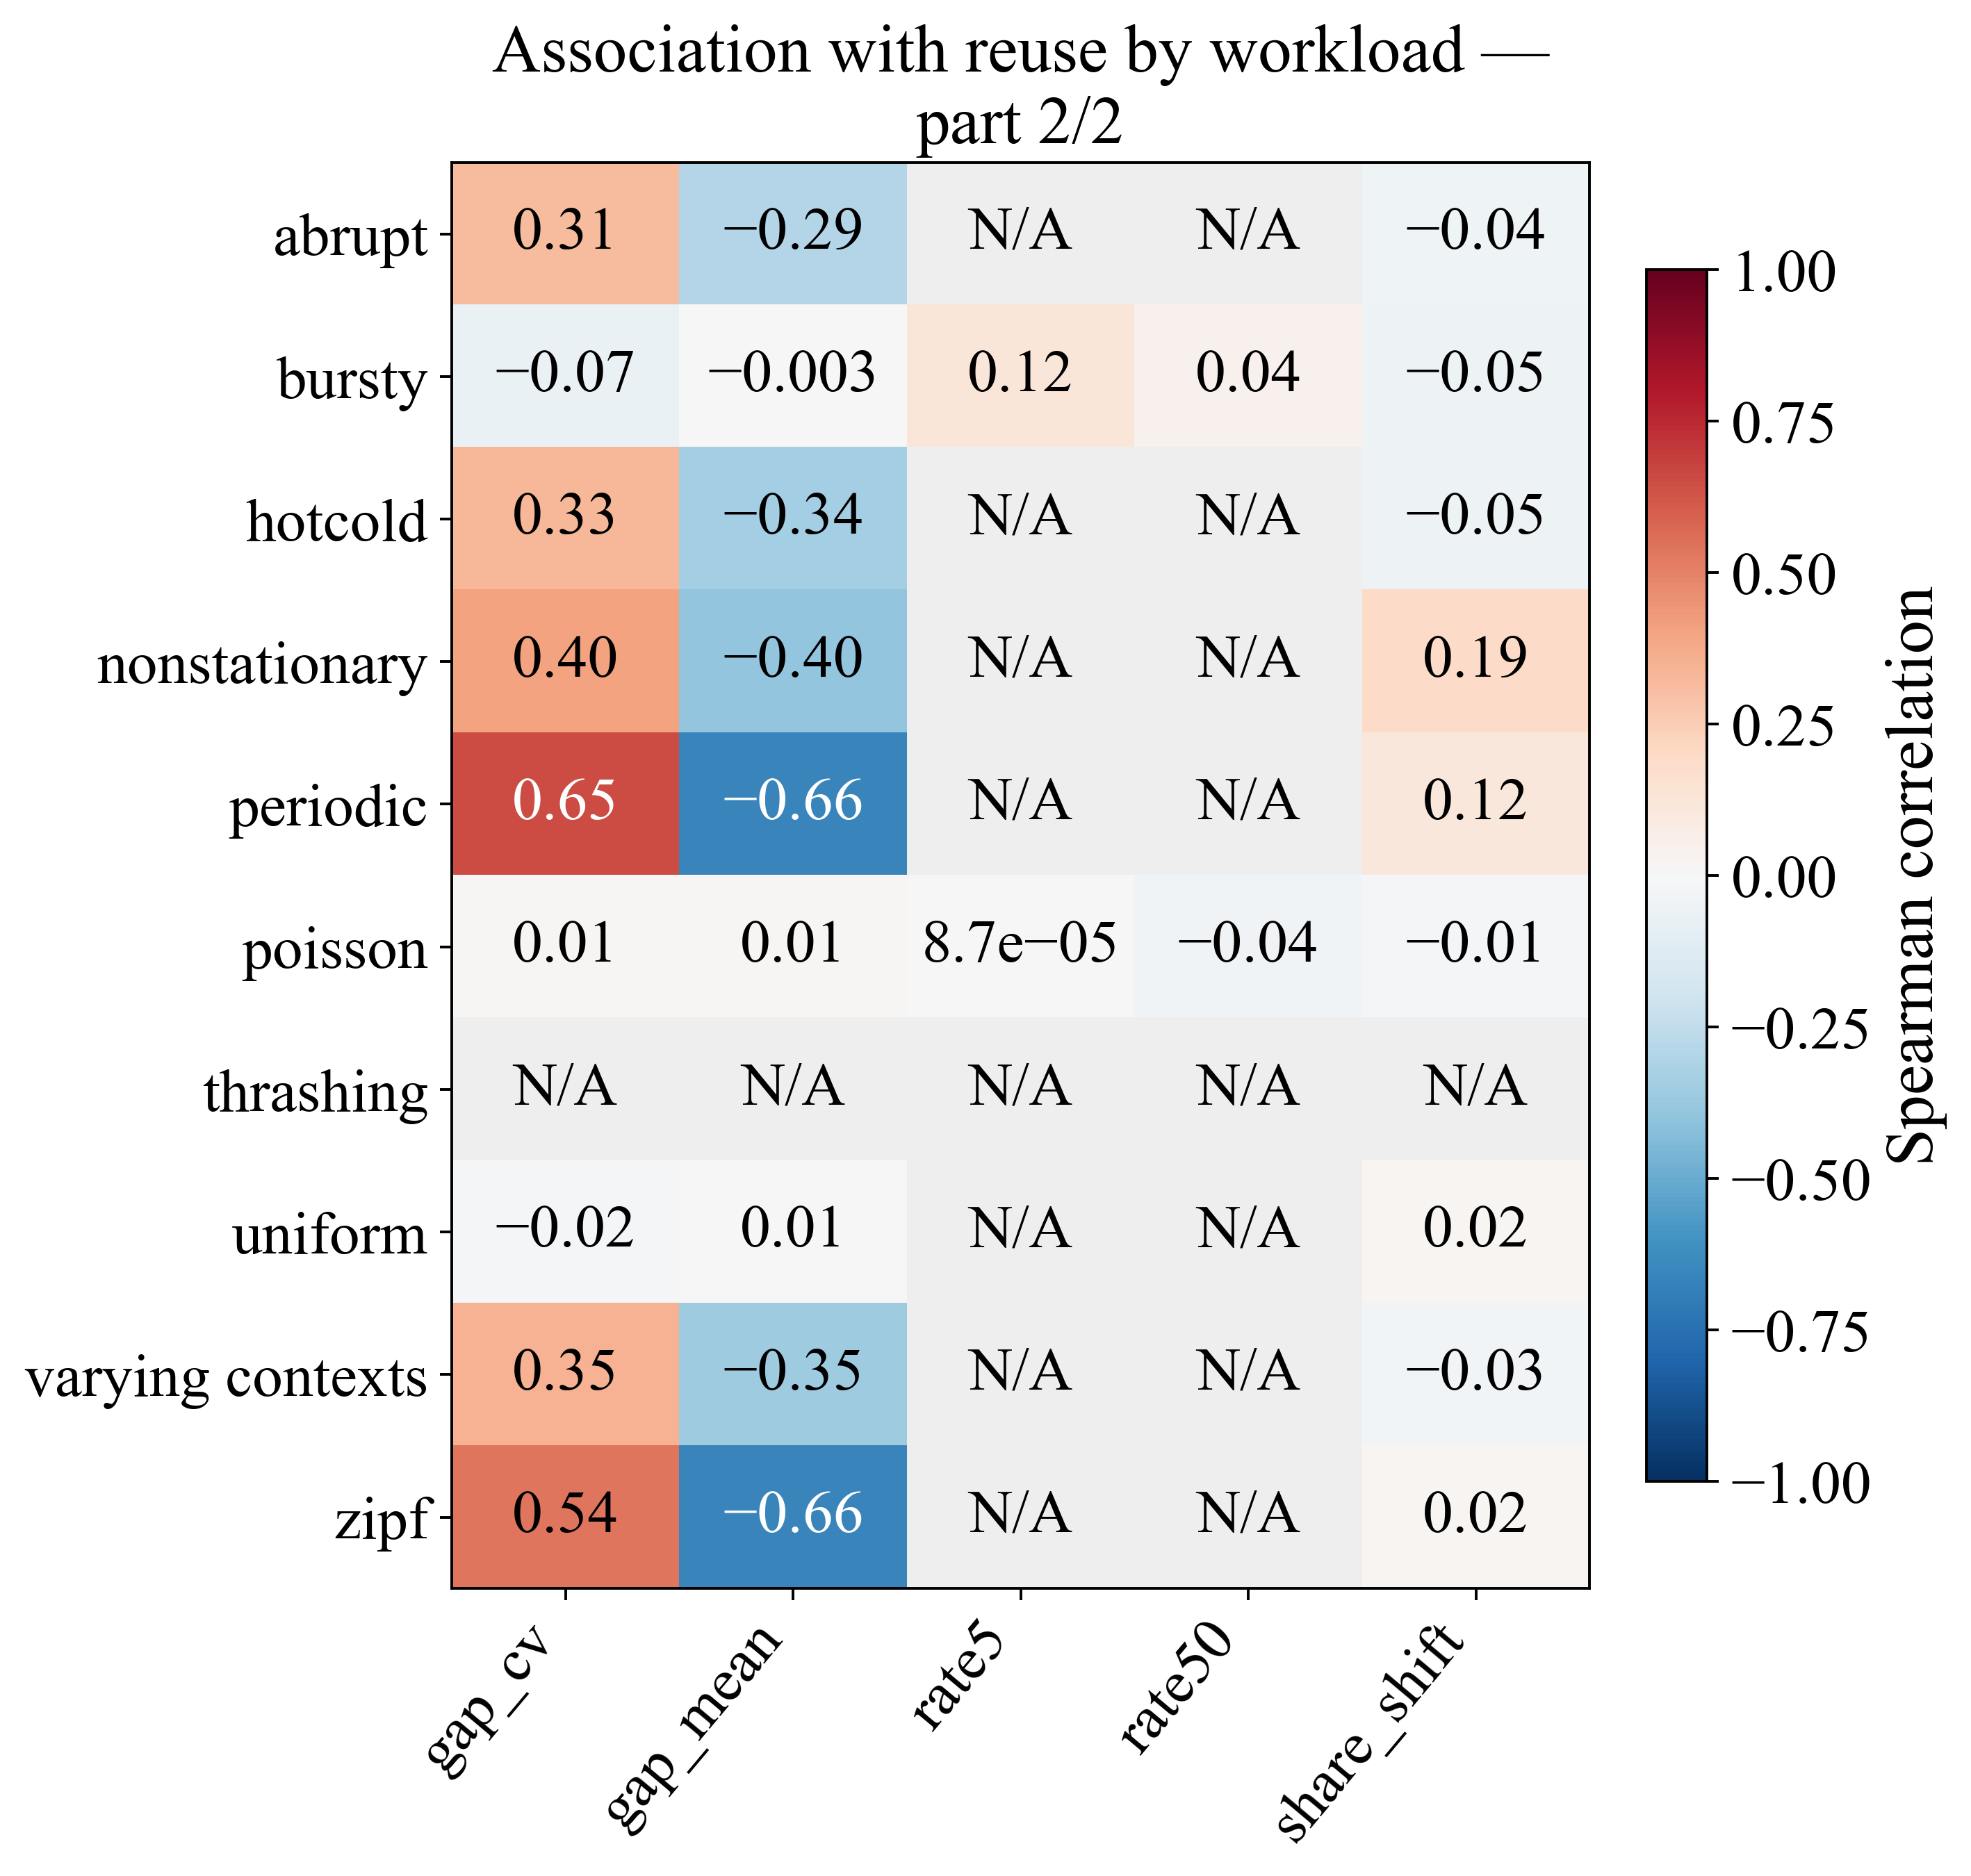

In [6]:
correlation=train[FEATURES].corr(method="spearman")
save_table(correlation,"feature_rank_correlation",show=False)
def feature_matrix_parts(frame, title, name):
    # Two column groups preserve every value without reducing 18 pt labels.
    for part, columns in enumerate((frame.columns[:6], frame.columns[6:]), start=1):
        values=frame.loc[:, columns]
        fig,ax=plt.subplots(figsize=(8.0,7.6),layout="constrained")
        cmap=mpl.colormaps["RdBu_r"].copy();cmap.set_bad("#eeeeee")
        im=ax.imshow(values,vmin=-1,vmax=1,cmap=cmap,aspect="auto")
        ax.set_xticks(range(len(columns)),columns,rotation=50,ha="right")
        ax.set_yticks(range(len(frame)),[str(x).replace("_"," ") for x in frame.index])
        for i in range(len(frame)):
            for j in range(len(columns)):
                value=values.iloc[i,j]
                label="N/A" if pd.isna(value) else (
                    f"{value:.1e}" if 0 < abs(value) < 0.0005 else
                    f"{value:.3f}" if 0.0005 <= abs(value) < 0.005 else
                    f"{value:.2f}"
                ).replace("-","−")
                ax.text(j,i,label,ha="center",va="center",fontsize=18,
                        color="white" if pd.notna(value) and abs(value)>.55 else "black")
        ax.set_title(f"{title} — part {part}/2")
        fig.colorbar(im,ax=ax,label="Spearman correlation",shrink=.85)
        save_figure(fig,f"{name}_part{part}",values.rename_axis("Row").reset_index())
feature_matrix_parts(correlation,"Training feature rank correlation","feature_rank_correlation")
stability=[]
for family,g in train.groupby("workload_id"):
    for feature in FEATURES:
        rho=spearmanr(g[feature],g.y10).statistic if g[feature].nunique()>1 and g.y10.nunique()>1 else np.nan
        stability.append((family,feature,rho))
stability=pd.DataFrame(stability,columns=["workload_id","feature","spearman_y10"])
save_table(stability.pivot(index="workload_id",columns="feature",values="spearman_y10"),"association_stability", show=False)

feature_matrix_parts(stability.pivot(index="workload_id",columns="feature",values="spearman_y10"),"Association with reuse by workload","association_stability")


## 02.6 — Exact forward-blocked folds and outer group separation

Three expanding-window folds are created **within training sessions only**. Validation starts 70 ms after the latest allowed training prediction time: 50 ms historical window plus the largest label horizon (20 ms). Validation blocks do not overlap. Early training and later validation can contain the same context within the same session; these folds estimate temporal extrapolation, while the independent development sessions estimate new-session generalization. There is no random row split. The largest horizon governs the gap even when fitting the primary 10 ms target.

Development is for model/policy choice and is not described as confirmatory evidence. Locked test sessions are generated only after the method is frozen. Any fitted imputer/scaler/calibrator must use the training side of each fold; neither imputation nor categorical encoding is currently necessary.

rows  sessions
fold role                       
1    train       11791        60
     validation   5879        60
2    train       23697        60
     validation   5906        60
3    train       35711        60
     validation   5923        60

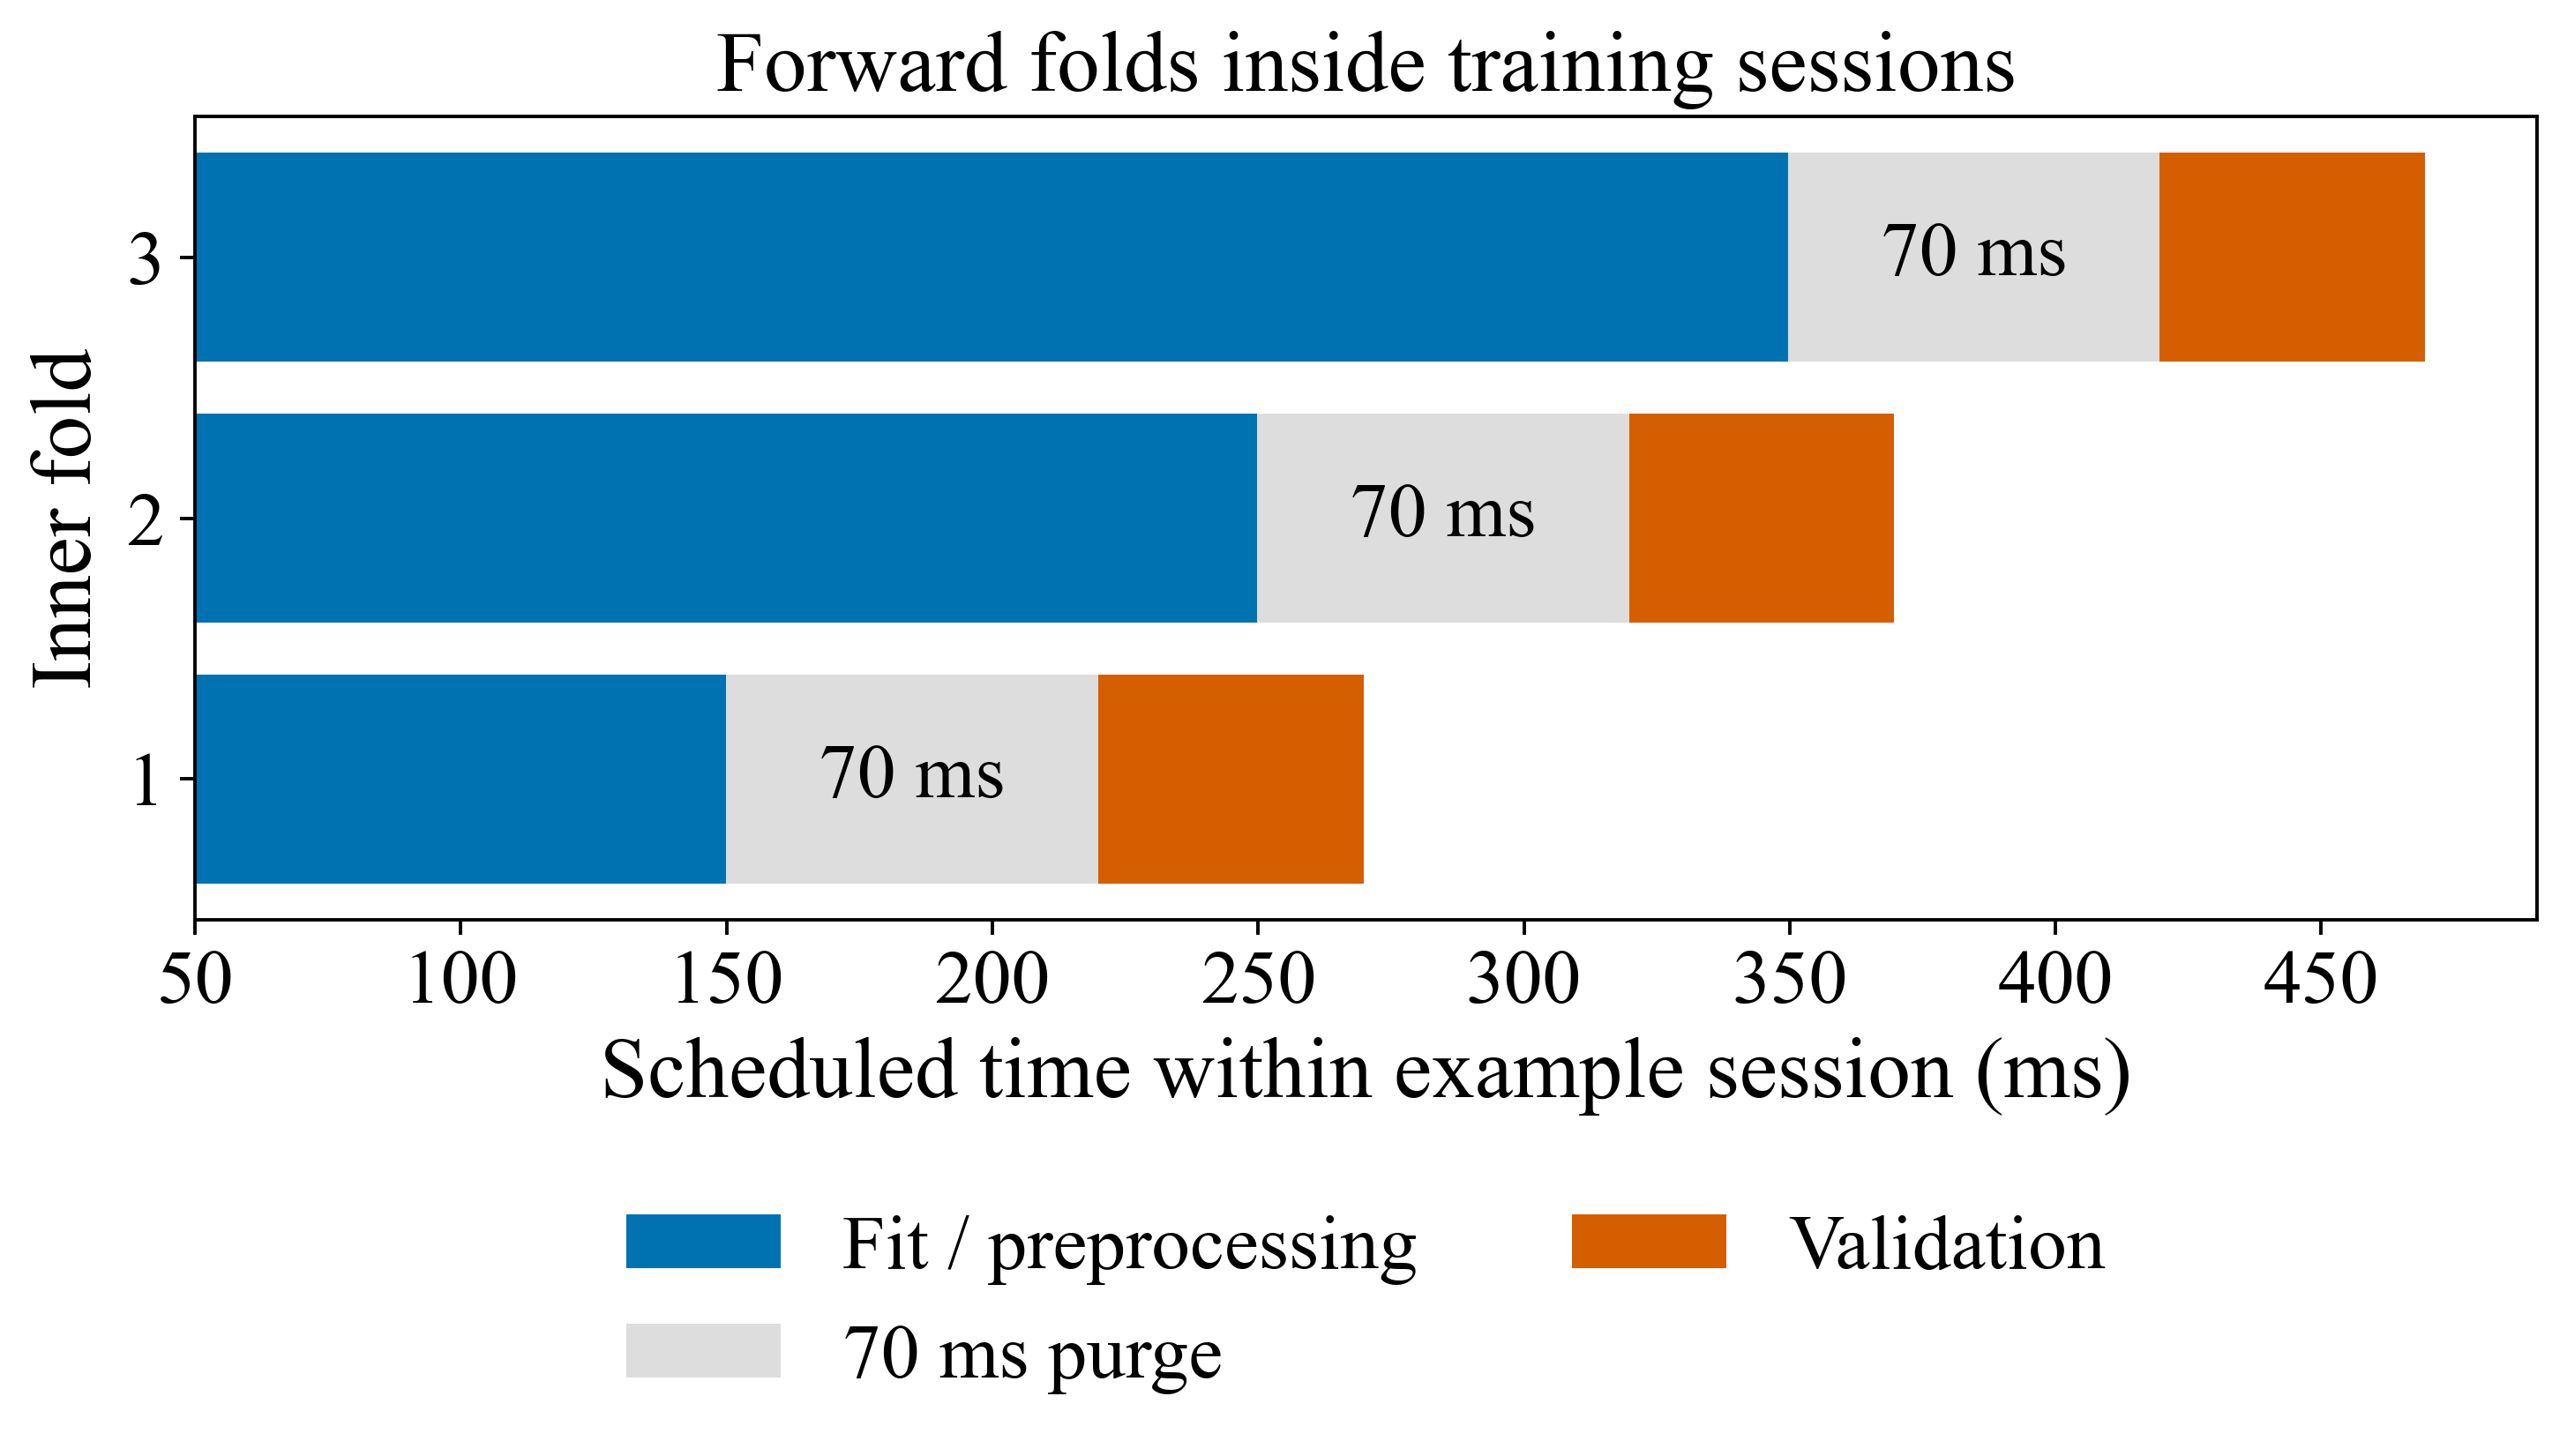

In [7]:
fold_parts=[]; boundaries=[]
for sid,g in train.groupby("session_id"):
    duration=features.loc[features.session_id.eq(sid),"schedule_ms"].max()
    for fold, fraction in enumerate([.30,.50,.70],1):
        cutoff=duration*fraction
        start=cutoff+PURGE_MS
        stop=min(start+duration*.10,duration-max(HORIZONS))
        a=g.loc[g.schedule_ms<=cutoff]
        b=g.loc[g.schedule_ms.between(start,stop,inclusive="left")]
        assert len(a)>0 and len(b)>0
        assert a.schedule_ms.max()+max(HORIZONS)<=b.schedule_ms.min()-HISTORY_MS
        for role,q in [("train",a),("validation",b)]:
            fold_parts.append(q[["row_id","session_id"]].assign(fold=fold,role=role))
        boundaries.append((sid,fold,cutoff,start,stop,len(a),len(b)))
folds=pd.concat(fold_parts,ignore_index=True)
assert not folds.loc[folds.role.eq("validation"),"row_id"].duplicated().any()
assert set(folds.session_id)<=train_ids
boundaries=pd.DataFrame(boundaries,columns=["session_id","fold","train_cutoff_ms","validation_start_ms","validation_stop_ms","train_rows","validation_rows"])
save_table(folds.groupby(["fold","role"]).agg(rows=("row_id","size"),sessions=("session_id","nunique")),"fold_sizes")
fig,ax=plt.subplots(figsize=(8.2,4.6))
example=boundaries.loc[boundaries.session_id.eq(sorted(train_ids)[0])]
for r in example.itertuples():
    ax.barh(r.fold,r.train_cutoff_ms-50,left=50,color=COLORS[0],label="Fit / preprocessing" if r.fold==1 else None)
    ax.barh(r.fold,70,left=r.train_cutoff_ms,color="#DDDDDD",label="70 ms purge" if r.fold==1 else None)
    ax.barh(r.fold,r.validation_stop_ms-r.validation_start_ms,left=r.validation_start_ms,color=COLORS[1],label="Validation" if r.fold==1 else None)
for r in example.itertuples():
    ax.text(r.train_cutoff_ms+35,r.fold,"70 ms",ha="center",va="center",fontsize=18)
ax.set(yticks=[1,2,3],ylabel="Inner fold",xlabel="Scheduled time within example session (ms)",title="Forward folds inside training sessions")
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.28),ncol=2,frameon=False)
save_figure(fig,"purged_folds",example)


## 02.7 — Freeze feature and split artifacts
Primary horizon is 10 ms, with 5 and 20 ms retained as prespecified sensitivity targets. It spans the 8.5 ms recurrence of the designed thrashing case without implying that those contexts fit in the cache. No class reweighting is imposed before probability calibration: proper probability losses will be reported along with prevalence, PR-AUC and calibration. Any later class weights must be selected inside the training folds.

In [8]:
definition={"version":"causal-v2-nanosecond-boundaries","features":FEATURES,"history_ms":50,"horizons_ms":HORIZONS,"primary_horizon_ms":10,"purge_ms":70,"clock":"scheduled_arrival_ns","decision":"after_current_request","outer_split":"independent_process_sessions","inner_split":"expanding_forward_blocks_with_70ms_purge","preprocessing":"StandardScaler fitted only on fold training rows for logistic regression; trees unscaled","categorical_predictors":[],"excluded":["key_id","workload_id","session_id","service_ns","cache_hit","future_reuse"],"energy_available":False}
# The fold boundaries are frozen: a re-run must reproduce them byte for byte.
_nb02_bound_path=DATA/"splits/inner_fold_boundaries_v1.csv"
_nb02_bound_bytes=boundaries.to_csv(index=False).encode("utf-8")
_nb02_bound_expected="3aa554f0f5aa179435a979b79a96d66cfad3824f53f2821658c84b040ca16410"
assert hashlib.sha256(_nb02_bound_bytes).hexdigest()==_nb02_bound_expected, "re-run changed the frozen split boundaries"
assert _nb02_bound_path.is_file() and _nb02_bound_path.read_bytes()==_nb02_bound_bytes, "Existing frozen split file is missing or differs; do not overwrite it"
# Bytes are identical: retain the existing file instead of rewriting it.
features.to_parquet(DATA/"processed/causal_features_v2.parquet",index=False)
folds.to_parquet(DATA/"splits/inner_purged_folds_v1.parquet",index=False)
(ROOT/"support/configs/feature_definition.json").write_text(json.dumps(definition,indent=2)+"\n")
paths=[DATA/"processed/causal_features_v2.parquet",DATA/"splits/inner_purged_folds_v1.parquet",DATA/"splits/inner_fold_boundaries_v1.csv",ROOT/"support/configs/feature_definition.json"]
hashes={acquisition_path(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}
(ROOT/"support/manifests/NotebookRuns/02_derived_hashes.json").write_text(json.dumps(hashes,indent=2)+"\n")
save_table(pd.DataFrame({"split":["train","development"],"rows":[len(train),len(dev)],"predictors":[len(FEATURES)]*2,"sessions":[train.session_id.nunique(),dev.session_id.nunique()]}).set_index("split"),"model_dimensions")


,rows,predictors,sessions
split,,,
train,51213,11,60
development,25610,11,30


## Conclusions

The artifact contains 51,213 eligible training rows from 60 sessions and 25,610 eligible development rows from 30 disjoint sessions, with eleven bounded historical predictors. The three inner validation blocks contain 5,879, 5,906 and 5,923 distinct rows; 70 ms separates each training boundary from validation. Prefix-mutation, truncation, bounded-history and independent-label checks all pass. Identifiers, workload labels and observed service times are excluded from predictors.

The largest marginal information estimates are for mean recent same-context gap (0.253 nats), truncated exponential history (0.250) and the 50 ms count (0.246). The 20 ms count and exponential history have rank correlation 0.964: coefficient stability and redundancy must be assessed in downstream models. Mutual information is a descriptive estimator, not a causal effect or a proof of forecast skill; repeated within-session rows are not independent replicates.

Within uniform and Poisson workloads, historical associations with the target are close to zero. Aggregate predictability partly reflects differences among designed workload families; this must be checked with regime-specific prediction errors. In thrashing, the 10 ms label is constant one, so within-regime correlations and ROC-AUC are undefined; missing coefficients are deliberately retained. Labels at 5 and 20 ms demonstrate strong horizon sensitivity.

No learned preprocessing or model has been fitted here. Notebook 03 will fit each transform inside its training fold, evaluate proper probability losses and calibration, and measure complete native policies on Raspberry Pi. Predictive accuracy alone cannot establish useful or secure cache management.